In [1]:
'''
detectability limits

can get the limit in flux and not in background - see what the dimmest actual star i trained on is
can look at how the efficiency of the NN looks depending on the brightness of the star
we can say that if the nn performs at baseline to all stars in the data, it would be x, otherwise it would be y.

make sure that the lightcurves are background subtracted when u do that

can put a scientific plot in

okay so then i get to say stuff about the upper limit


the other papers we’re looking at are looking at not associated with a star

can get number of star hours above a certain magnitude and the upper limit based on the detectability'''

'look at final cands again maybe??'

In [2]:
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt
import precision_recall as pr
import gc  # garbage collector
import review_findings_functions as rff
import os
import importlib

plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

In [3]:
#step one: see what the flux of the dimmest star i trained on is
#okay so actually we need to extract light curves
save_dir = '/lustre/lrspec/ZTF_data/lightcurves/training/'

In [22]:
def load_xy_positions_from_info(info_path):
    info = np.load(info_path)
    xy_array = info[:,2:4]
    xy_array = np.unique(xy_array, axis=0)
    return xy_array

In [23]:
load_xy_positions_from_info('/lustre/lrspec/ZTF_data/training_feb26/offcenter_stamps_streaks/info/ztf_20220820237546_000798_zr_c01_x_0004._2_stamps_info.npy')

array([[ 174,  715],
       [ 248, 2383],
       [ 264,  854],
       [1480,  506],
       [1503, 2697],
       [1546,  485],
       [1817, 2303],
       [2194, 1452],
       [2300, 2495],
       [2430, 1925]])

In [3]:
info_test = np.load('/lustre/lrspec/ZTF_data/training_feb26/offcenter_stamps_streaks/info/ztf_20220820237546_000798_zr_c01_x_0004._2_stamps_info.npy')

In [15]:
'ztf_20220820237546_000798_zr_c01_x_0004._2_stamps_info.npy'[:40]

'ztf_20220820237546_000798_zr_c01_x_0004.'

In [85]:
lc_filename = 'lightcurve_ztf_20220820237546_000798_zr_c01_x_0004_2_0174_0715.csv'

In [86]:
lc = pd.read_csv('/lustre/lrspec/ZTF_data/lightcurves/1020/'+lc_filename)

FileNotFoundError: [Errno 2] No such file or directory: '/lustre/lrspec/ZTF_data/lightcurves/1020/lightcurve_ztf_20220820237546_000798_zr_c01_x_0004_2_0174_0715.csv'

In [4]:
info_test

array([[   0,    0,  174,  715,    0],
       [   0,    0,  174,  715,    1],
       [   0,    0,  174,  715,    2],
       [   0,    0,  174,  715,   -1],
       [   0,    0,  174,  715,   -2],
       [   0,    0,  248, 2383,    0],
       [   0,    0,  248, 2383,    1],
       [   0,    0,  248, 2383,    2],
       [   0,    0,  248, 2383,   -1],
       [   0,    0,  248, 2383,   -2],
       [   0,    0,  264,  854,    0],
       [   0,    0,  264,  854,    1],
       [   0,    0,  264,  854,    2],
       [   0,    0,  264,  854,   -1],
       [   0,    0,  264,  854,   -2],
       [   0,    0, 1480,  506,    0],
       [   0,    0, 1480,  506,    1],
       [   0,    0, 1480,  506,    2],
       [   0,    0, 1480,  506,   -1],
       [   0,    0, 1480,  506,   -2],
       [   0,    0, 1503, 2697,    0],
       [   0,    0, 1503, 2697,    1],
       [   0,    0, 1503, 2697,    2],
       [   0,    0, 1503, 2697,   -1],
       [   0,    0, 1503, 2697,   -2],
       [   0,    0, 1546,

Loading FITS file: /lustre/lrspec/ZTF_data/2022/1017/ztf_20221017148750_000831_zi_c03_x_0021.fits.fz
Processing 10 positions...
Calculating background...
Image shape: (3080, 3072)
Background value: 196.38
saving
/lustre/lrspec/ZTF_data/lightcurves/training/lightcurve_ztf_20221017148750_000831_zi_c03_x_0021.fits.fz_4_0295_0812.csv
saving
/lustre/lrspec/ZTF_data/lightcurves/training/lightcurve_ztf_20221017148750_000831_zi_c03_x_0021.fits.fz_4_0306_1037.csv
saving
/lustre/lrspec/ZTF_data/lightcurves/training/lightcurve_ztf_20221017148750_000831_zi_c03_x_0021.fits.fz_4_0492_2968.csv
saving
/lustre/lrspec/ZTF_data/lightcurves/training/lightcurve_ztf_20221017148750_000831_zi_c03_x_0021.fits.fz_4_0783_0430.csv
saving
/lustre/lrspec/ZTF_data/lightcurves/training/lightcurve_ztf_20221017148750_000831_zi_c03_x_0021.fits.fz_4_0963_0802.csv
saving
/lustre/lrspec/ZTF_data/lightcurves/training/lightcurve_ztf_20221017148750_000831_zi_c03_x_0021.fits.fz_4_1532_2023.csv
saving
/lustre/lrspec/ZTF_data/li

KeyboardInterrupt: 

In [31]:
lc_test = pd.read_csv('/lustre/lrspec/ZTF_data/lightcurves/training/lightcurve_ztf_20221017148750_000831_zi_c03_x_0021.fits.fz_4_0295_0812.csv')

In [32]:
lc_test

,position_id,x_input,y_input,row_index,flux_hap_2,flux_hap_3,flux_hap_4,flux_hap_5,max_col
0,0,295,812,0,750.074036,1262.256104,1794.390259,2376.326904,295.0
1,0,295,812,1,739.300659,1228.791016,1748.938477,2308.990234,295.0
2,0,295,812,2,731.924438,1240.279053,1783.002686,2379.033447,295.0
3,0,295,812,3,700.312134,1184.134521,1686.678467,2242.711914,295.0
4,0,295,812,4,733.076050,1269.718262,1828.783569,2448.924316,295.0
...,...,...,...,...,...,...,...,...,...
3075,0,295,812,3075,686.143677,1235.870361,1844.632202,2502.113037,294.0
3076,0,295,812,3076,687.905334,1221.744385,1823.190918,2477.567871,294.0
3077,0,295,812,3077,647.222717,1149.270142,1713.957520,2311.284424,294.0
3078,0,295,812,3078,666.627014,1188.294189,1770.345459,2389.471436,294.0


In [ ]:
#great so it works we have lcs now
#now we need to figure out:
#a) how low they go
#b) their correctly-predicted-ness as a function of flux

In [41]:
avg_fluxes = []
lc_folder = '/lustre/lrspec/ZTF_data/lightcurves/training/'
for file in os.listdir(lc_folder):
    lc = pd.read_csv(os.path.join(lc_folder, file))['flux_hap_2']
    avg_fluxes.append(np.average(lc))

In [46]:
np.min(avg_fluxes)

130.61321985319063

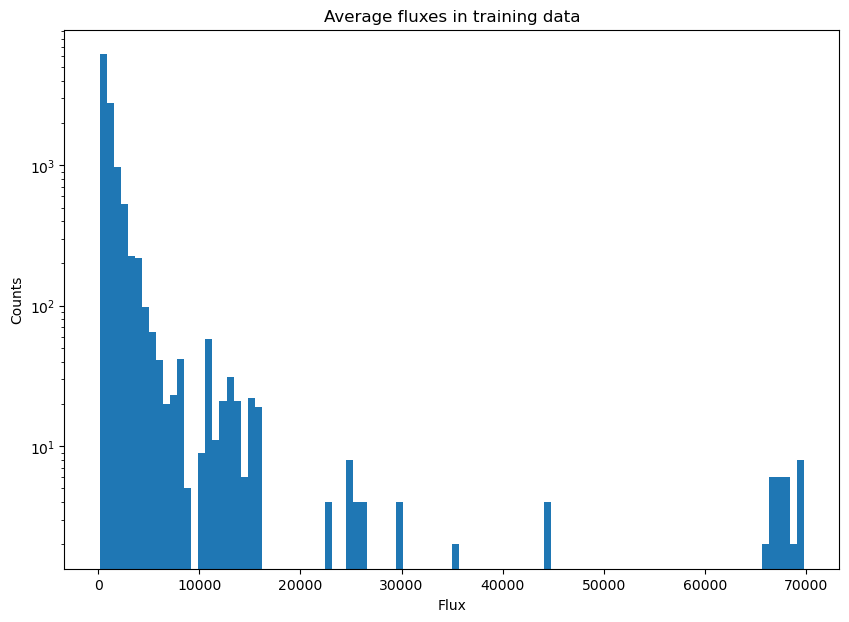

In [42]:
plt.hist(avg_fluxes, bins=100)
plt.yscale('log')
# plt.xscale('log')

plt.title('Average fluxes in training data')
plt.xlabel('Flux')
plt.ylabel('Counts')
plt.show()

In [37]:
%matplotlib inline

In [50]:
!pip install pyarrow

Defaulting to user installation because normal site-packages is not writeable
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 159.2 kB/s eta 0:00:0000:0100:01
  Installing build dependencies ... error
  error: subprocess-exited-with-error
  
  × pip subprocess to install build dependencies did not run successfully.
  │ exit code: 1
  ╰─> [905 lines of output]
           ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/278.3 kB ? eta -:--:--
           ━━━━╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 30.7/278.3 kB 144.7 MB/s eta 0:00:01
           ━━━━╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 30.7/278.3 kB 144.7 MB/s eta 0:00:01
           ━━━━╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 30.7/278.3 kB 144.7 MB/s eta 0:00:01
           ━━━━╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 30.7/278.3 kB 144.7 MB/s eta 0:00:01
           ━━━━╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 30.7/278.3 kB 144.7 MB/s eta 0:00:01
           ━━━━╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 30.7/278.3 kB 144.7 MB/s eta 0:00:01
           ━━━━╺━━━━━━━━━━━━

In [62]:
#okay collecting avg fluxes now, and then
#ill have to remember to remove 0029s

In [3]:
fluxes = np.load('/lustre/lrspec/ZTF_data/lightcurves/average_fluxes_1020.npy')

In [4]:
df = pd.DataFrame(fluxes)

In [17]:
df.loc[0,0][46:50]

'0023'

In [18]:
fluxes_no_29 = df[df[0].str[46:50] != '0029']

In [21]:
len(df)-len(fluxes_no_29), len(fluxes_no_29)

(24477, 698669)

In [19]:
fluxes_no_29

,0,1
0,lightcurve_ztf_20221020138241_000686_zi_c11_x_...,879.2234773710177
1,lightcurve_ztf_20221020148032_000686_zg_c13_x_...,134.01331253547173
2,lightcurve_ztf_20221020157697_000640_zi_c01_x_...,68.94194593058003
3,lightcurve_ztf_20221020138241_000686_zi_c04_x_...,33.9270216112013
4,lightcurve_ztf_20221020163819_000640_zg_c10_x_...,90.0123512416691
...,...,...
723141,lightcurve_ztf_20221020138241_000686_zi_c13_x_...,81.27483291625977
723142,lightcurve_ztf_20221020163819_000640_zg_c12_x_...,2904.682248677836
723143,lightcurve_ztf_20221020148032_000686_zg_c07_x_...,99.94683338016658
723144,lightcurve_ztf_20221020163819_000640_zg_c16_x_...,106.90212204673074


In [28]:
fluxes_no_29[1] = pd.to_numeric(fluxes_no_29[1], errors='coerce')

/tmp/ipykernel_46437/4211184265.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fluxes_no_29[1] = pd.to_numeric(fluxes_no_29[1], errors='coerce')


In [29]:
%matplotlib inline

In [35]:
np.min(fluxes_no_29[1])

-97.31472824889345

In [39]:
np.sum(fluxes_no_29[1] > 130)

422263

In [40]:
np.sum(fluxes_no_29[1] < 130)

276406

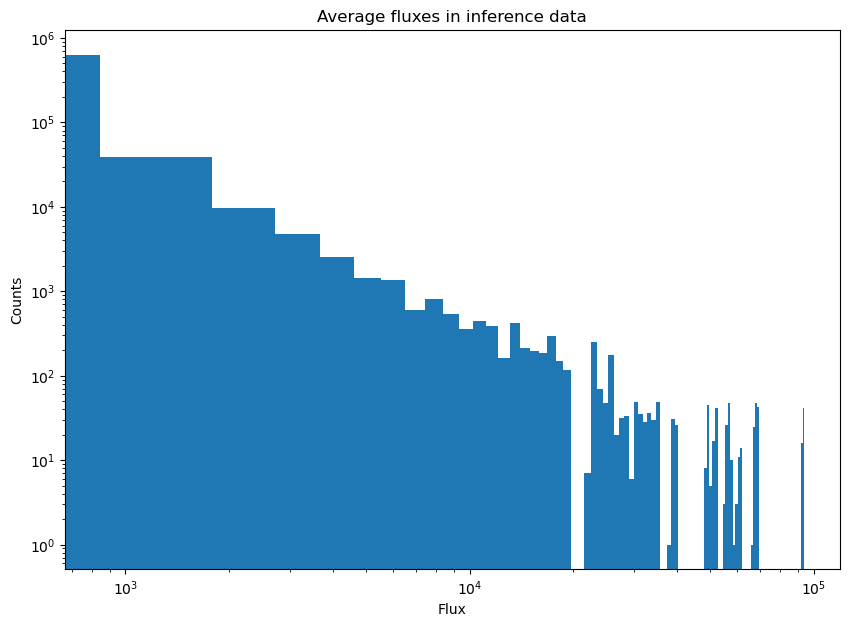

In [38]:
plt.hist(fluxes_no_29[1], bins=100)
plt.title('Average fluxes in inference data')
plt.xlabel('Flux')
plt.ylabel('Counts')
plt.yscale('log')
plt.xscale('log')
plt.show()


In [ ]:
#in the meantime, let's check on...the efficiency data ig? 
#to figure out how well we do as a function of brightness
#how do we not have lcs of eff data
#we must cause i literally have a script for that
#okay yeah it's in 
#/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_pos/lightcurves_pos/
#are we worried about the average getting higher cause of our implanted transients?
#for now let's....not worry about it

In [43]:
save_name='offset_sat_newhparam_b50_allstamps_satdumbsplit_folds'

In [90]:
df_implants_neg = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_neg/df_implants_neg")
df_implants_pos = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_pos/df_implants_pos")


In [71]:
len(df_implants_pos)

800

In [69]:
negdir = "/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_neg/predsarrays_average/"

In [70]:
def get_efficiency(df, df_implant, distance_threshold, posneg):
    df_cut = df[df['dist_to_implant']<=distance_threshold]
    df_cut = df_cut[df_cut['type']==posneg]
    df_cut.drop_duplicates(subset=["filename", "quad", "type","row_from_implant", "col_from_implant"], inplace=True)
    return len(df_cut),len(df_implant)

In [76]:
thr = "0.99"
test_name = "average"

In [77]:
df_pos = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_"+'pos'+"/predsarrays_"+test_name+"/df_matched_thr_"+thr)
df_neg = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_"+'neg'+"/predsarrays_"+test_name+"/df_matched_thr_"+thr)


In [78]:
df_implants_neg

,Unnamed: 0,filename,row_from_implant,col_from_implant,A_from_implant,sig_from_implant,quad_from_implant
0,0,ztf_20221020294271_000449_zr_c04_x_0004.,424.0,113.0,0.950,7.0,3
1,1,ztf_20221020294271_000449_zr_c04_x_0004.,425.0,696.0,0.600,6.0,3
2,2,ztf_20221020294271_000449_zr_c04_x_0004.,425.0,1199.0,0.990,9.0,3
3,3,ztf_20221020294271_000449_zr_c04_x_0004.,425.0,1840.0,0.400,7.0,3
4,4,ztf_20221020294271_000449_zr_c04_x_0004.,425.0,2410.0,0.600,5.0,3
...,...,...,...,...,...,...,...
795,795,ztf_20221020154120_000640_zi_c03_x_0002.,2999.0,120.0,0.950,5.0,3
796,796,ztf_20221020154120_000640_zi_c03_x_0002.,3000.0,685.0,0.995,4.0,3
797,797,ztf_20221020154120_000640_zi_c03_x_0002.,2999.0,1240.0,0.950,4.0,3
798,798,ztf_20221020154120_000640_zi_c03_x_0002.,2999.0,1843.0,0.400,7.0,3


In [120]:
def get_lcpath_from_eff_df_row(df_row, posneg):
    dir_path = '/lustre/lrspec/ZTF_data/lightcurves/1020/'
    filename = df_row['filename']
    quad = df_row['quad_from_implant']
    lc_filename = 'lightcurve_'+df_row['filename'][:-1]+'_'+str(quad)+'_'+f'{int(df_row["closest_x"]):04}'+'_'+f'{int(df_row["closest_y"]):04}'+".csv"
    return(os.path.join(dir_path, lc_filename))

In [ ]:
#okay so we gotta make those light curves

In [ ]:
'lightcurve_ztf_20221020154120_000640_zi_c03_x_0002._2.npy_2_0007_2959.csv'

In [123]:
get_lcpath_from_eff_df_row(df_implants_pos_use.iloc[2], 'pos')

'/lustre/lrspec/ZTF_data/lightcurves/1020/lightcurve_ztf_20221020138241_000686_zi_c05_x_0000_3_0165_0695.csv'

In [116]:
#so what we need to do is calculate the average (bg subtracted) flux for all of those guys
#which we did, more or less
#but now we need to match it to the lc coordinates
posneg='neg'
for i, row in df_implants_neg_use.iterrows():
    lcpath = get_lcpath_from_eff_df_row(row, posneg)
    lc = pd.read_csv(lcpath)['flux_hap_2']
    df_implants_neg_use.loc[i, 'avg_flux']=np.average(lc)

/tmp/ipykernel_64034/4169214350.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_implants_neg_use.loc[i, 'avg_flux']=np.average(lc)


In [ ]:
#okay so we SHOULDNET do that
#instead let's look at the original LCs and use the flux values on those

(array([365., 160.,  60.,  45.,  35.,  15.,  45.,  30.,  10.,  20.]),
 array([0.0231448 , 0.23904457, 0.45494434, 0.67084411, 0.88674388,
        1.10264364, 1.31854341, 1.53444318, 1.75034295, 1.96624272,
        2.18214249]),
 <BarContainer object of 10 artists>)

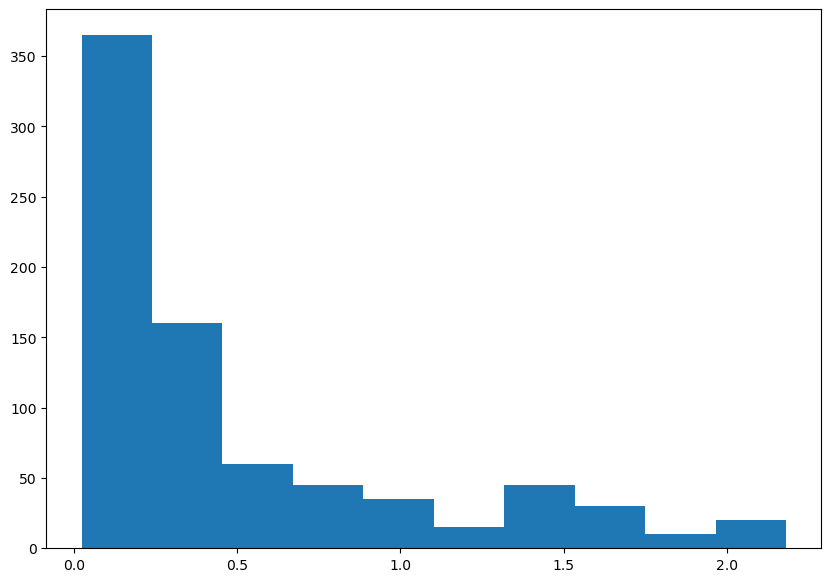

In [117]:
plt.hist(df_implants_neg_use['avg_flux'])

In [112]:
df_implants_neg_use = df_implants_neg[np.abs(df_implants_neg['Diff'])<20]

In [113]:
df_implants_pos_use = df_implants_pos[np.abs(df_implants_pos['Diff'])<20]

In [114]:
len(df_implants_pos_use), len(df_implants_pos)

(785, 800)

In [94]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

In [101]:
df_implants_pos = rff.match_stars_eff(df_implants_pos)

/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/ztf_20221020138241_000686_zi_c05_x_3.fits
3
/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/ztf_20221020138241_000686_zi_c05_x_3.fits
3
/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/ztf_20221020138241_000686_zi_c05_x_3.fits
3
/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/ztf_20221020138241_000686_zi_c05_x_3.fits
3
/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/ztf_20221020138241_000686_zi_c05_x_3.fits
3
/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/ztf_20221020138241_000686_zi_c05_x_3.fits
6
/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/ztf_20221020138241_000686_zi_c05_x_3.fits
6
/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/ztf_20221020138241_000686_zi_c05_x_3.fits
6
/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/ztf_20221020138241_000686_zi_c05_x_3.fits
6
/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/ztf_20221020138241_000686_zi_c05_x_3.fits
6


In [99]:
%matplotlib inline

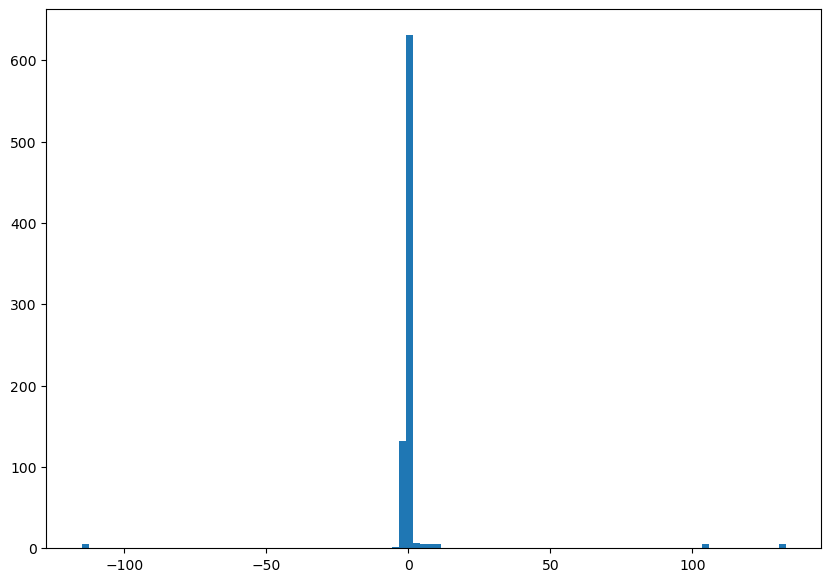

In [104]:
plt.hist(df_implants_neg['Diff'], bins=100)
plt.show()

In [ ]:
#okay so the right way to do it would be to take the average without the transient
#of the training data
#cause there isn't that much eff data i don't really trust it
#so the question is how hard is it to get to the original lc from the training data stamps
#answer: relies on redoing a bunch of stuff that should be fixed but...
#let's just extrapolate from the numbers and it'll be slightly wrong, for now

In [47]:
our_targ_te = np.load("/lustre/lrspec/ZTF_data/saved_loss/our_targ_te_"+save_name+".npy") 
targ_te = np.load("/lustre/lrspec/ZTF_data/saved_loss/targ_te_"+save_name+".npy") 
our_feat_te = np.load("/lustre/lrspec/ZTF_data/saved_loss/our_feat_te_"+save_name+".npy")

In [53]:
our_feat_te = np.load("/lustre/lrspec/ZTF_data/saved_loss/our_feat_te_"+save_name+".npy")
our_pred_te_max = np.load("/lustre/lrspec/ZTF_data/saved_loss/our_pred_te_max_"+save_name+'.npy') #NOTE ITS MAX

In [51]:
our_targ_te.shape

(28700,)

In [55]:
our_pred_te_max.shape

(28700,)

In [91]:
def get_avg_streak_from_stamp(stamp):
    argmax_to_get_middle = np.argmax(np.average(stamp, axis=0))
    lc = np.sum(stamp[:,argmax_to_get_middle-2:argmax_to_get_middle+3], axis=1)
    avg= np.average(lc)
    extrapolated_average = avg*(3080/len(lc))
    return extrapolated_average

In [71]:
stamp = our_feat_te[1]

In [89]:
argmax_to_get_middle = np.argmax(np.average(stamp, axis=0))
lc = np.sum(stamp[:,argmax_to_get_middle-2:argmax_to_get_middle+3], axis=1)
avg= np.average(lc)
extrapolated_average = avg*(3080/len(lc))

In [90]:
extrapolated_average

111.53821076750755

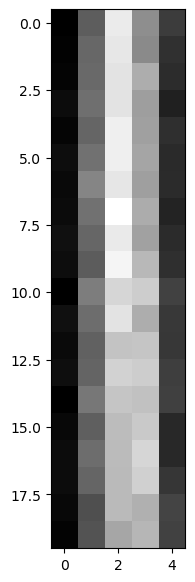

In [79]:
plt.imshow(stamp[:,argmax_to_get_middle-2:argmax_to_get_middle+3])

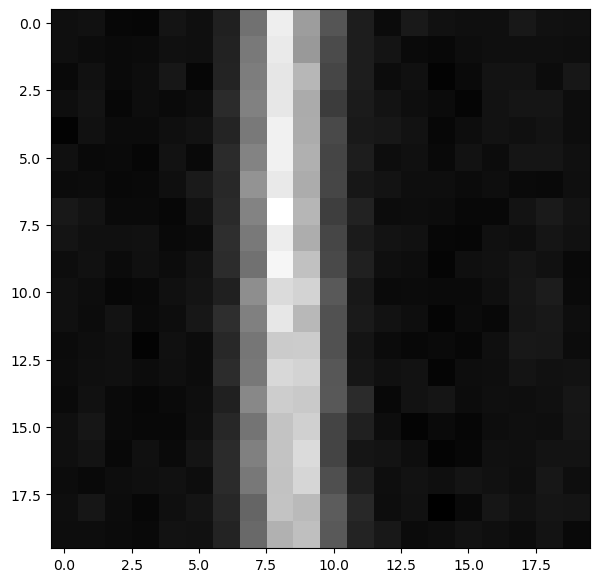

In [74]:
plt.imshow(our_feat_te[1])

In [94]:
avgs = []
for i, stamp in enumerate(our_feat_te):
    avg = get_avg_streak_from_stamp(stamp)
    avgs.append(avg)

In [99]:
np.min(avgs)

0.0

In [104]:
right_or_not = []
for i, number in enumerate(our_pred_te_max):
    if number==our_targ_te[i]:
        right_or_not.append(1)
    else:
        right_or_not.append(0)

In [124]:
right_or_not_pos = []
for i, number in enumerate(our_pred_te_max):
    if our_targ_te[i]==1:
        if number==our_targ_te[i]:
            right_or_not_pos.append(1)
        else:
            right_or_not_pos.append(0)

In [ ]:
avgs_pos = []
for i, stamp in enumerate(our_feat_te):
    if our_targ_te[i]==1:
        avg = get_avg_streak_from_stamp(stamp)
        avgs_pos.append(avg)

In [132]:
get_avg_streak_from_stamp(stamp)

144.31950381472709

In [137]:
np.array(right_or_not_pos)==1

array([ True, False,  True, ...,  True,  True,  True])

In [135]:
[right_or_not_pos==1]

array([], shape=(0, 14350), dtype=float64)

In [144]:
len(np.array(avgs_pos)[np.array(right_or_not_pos)==1])

10253

In [145]:
len(np.array(avgs_pos)[np.array(right_or_not_pos)==0])

4097

In [169]:
b1.shape

(30,)

In [167]:
(n1/(n1+n2)).shape

(29,)

Text(0.5, 1.0, 'brightness (incorrectly calculated) vs percentage correct per bin')

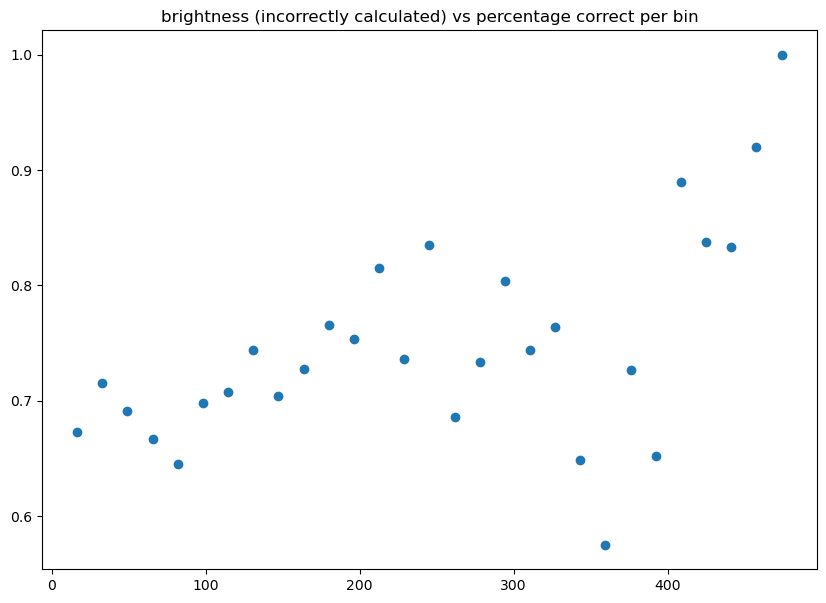

In [172]:
plt.scatter(b1[1:], n1/(n1+n2))
plt.title('brightness (incorrectly calculated) vs percentage correct per bin')

In [160]:
bins = np.linspace(np.min(avgs_pos), np.max(avgs_pos), 30)

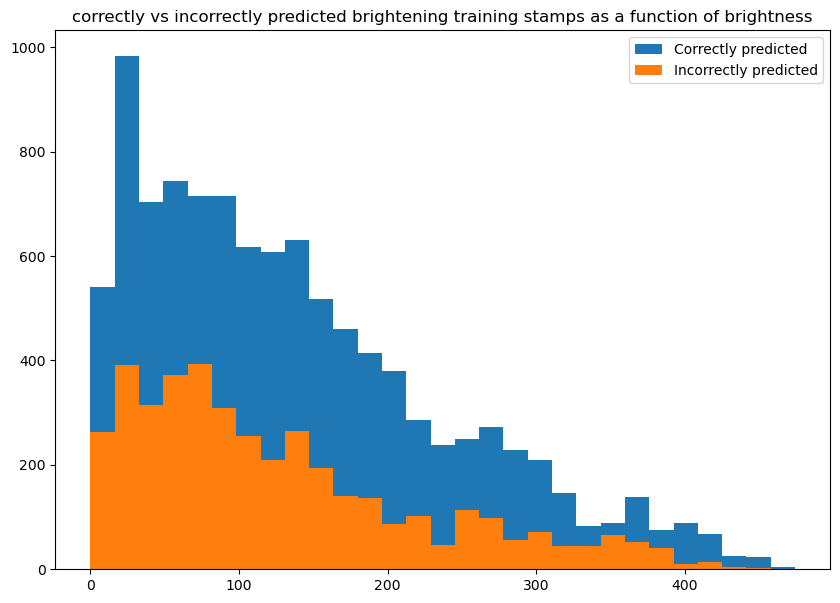

In [161]:
n1, b1, other = plt.hist(np.array(avgs_pos)[np.array(right_or_not_pos)==1], bins=bins, label="Correctly predicted")
n2, b2, other = plt.hist(np.array(avgs_pos)[np.array(right_or_not_pos)==0], bins=bins, label="Incorrectly predicted")

plt.title("correctly vs incorrectly predicted brightening training stamps as a function of brightness")
plt.legend()
plt.show()

Text(0.5, 1.0, 'color is whether it was predicted correctly or not')

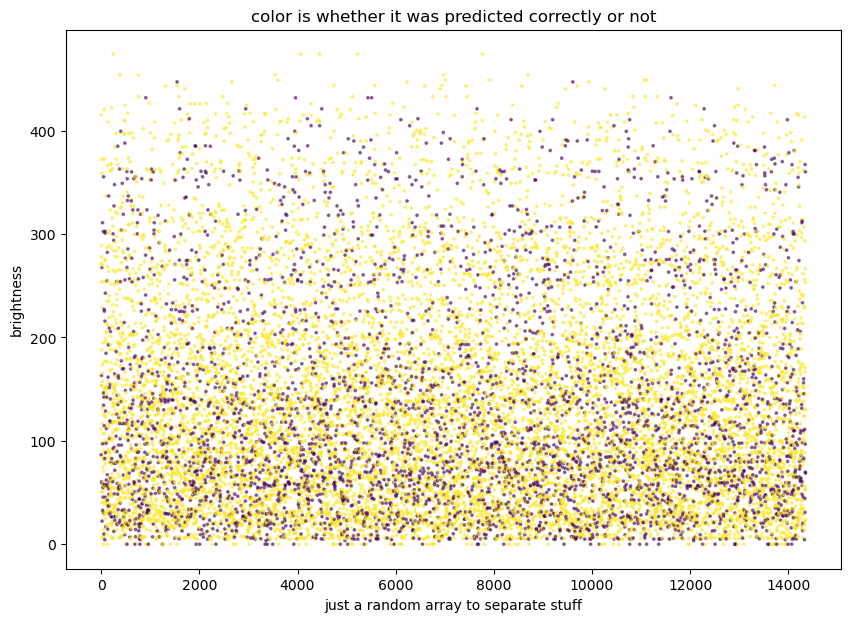

In [128]:
plt.scatter(np.linspace(0, len(right_or_not_pos),len(right_or_not_pos)),avgs_pos, c=right_or_not_pos, cmap='viridis',alpha=.5, s=3)
plt.xlabel('just a random array to separate stuff')
plt.ylabel('brightness')
plt.title('color is whether it was predicted correctly or not')

Text(0.5, 1.0, 'color is whether it was predicted correctly or not')

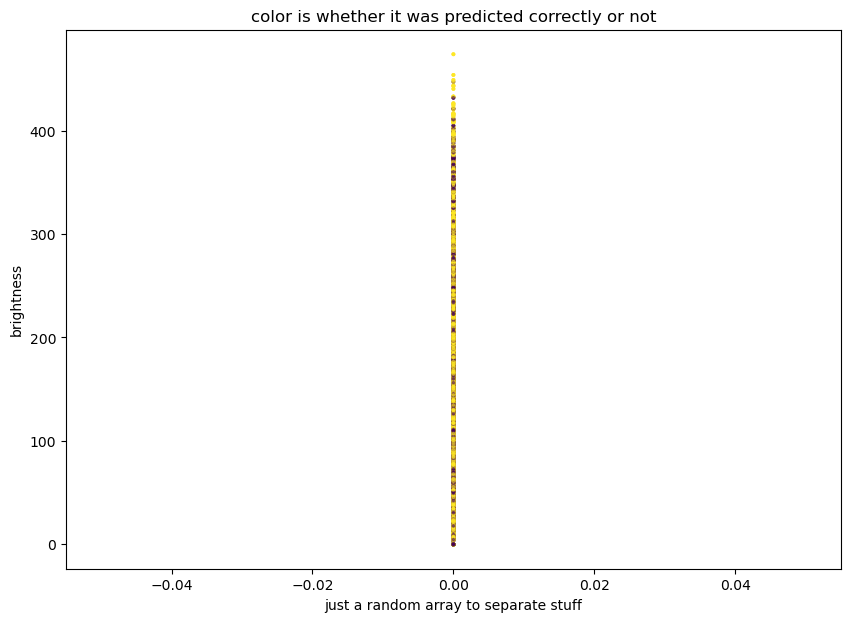

In [121]:
plt.scatter(np.linspace(0, 0,len(avgs)),avgs, c=right_or_not, cmap='viridis',alpha=.5, s=3)
plt.xlabel('just a random array to separate stuff')
plt.ylabel('brightness')
plt.title('color is whether it was predicted correctly or not')

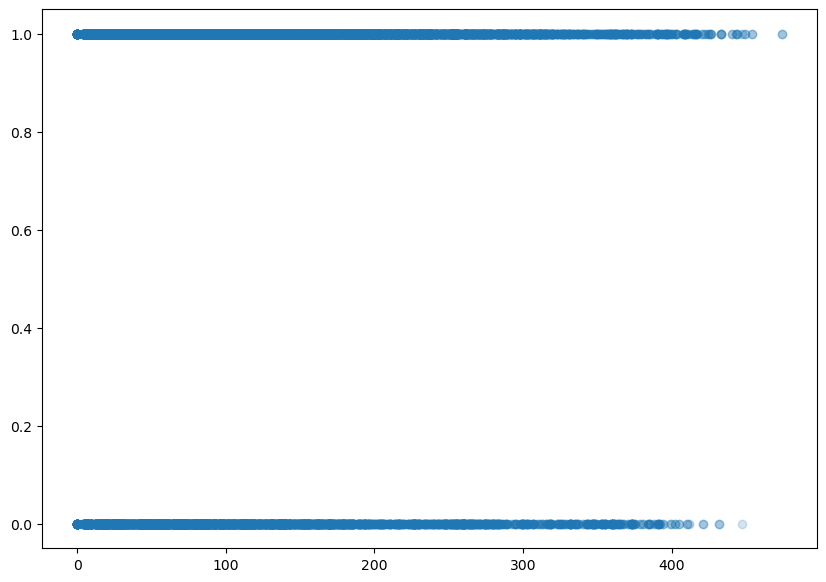

In [107]:
plt.scatter(avgs,right_or_not, alpha=.1)

(array([300., 735., 470., 756., 933., 789., 765., 527., 589., 687., 699.,
        706., 718., 767., 708., 694., 703., 630., 647., 628., 551., 461.,
        523., 640., 504., 502., 463., 517., 476., 524., 498., 343., 435.,
        401., 391., 386., 332., 320., 310., 301., 327., 286., 306., 226.,
        201., 255., 189., 215., 198., 232., 189., 147., 184., 295., 194.,
        206., 156., 198., 152., 148., 155.,  73., 124., 139.,  98., 108.,
         93.,  80.,  73.,  88.,  61.,  55.,  55.,  80.,  70.,  80., 101.,
         55.,  85.,  30.,  27.,  35.,  62.,  40.,  35.,  15.,  40.,  30.,
         10.,  20.,   0.,  15.,   5.,  10.,  10.,   5.,   0.,   0.,   0.,
          5.]),
 array([  0.        ,   4.74022865,   9.4804573 ,  14.22068595,
         18.9609146 ,  23.70114324,  28.44137189,  33.18160054,
         37.92182919,  42.66205784,  47.40228649,  52.14251514,
         56.88274379,  61.62297243,  66.36320108,  71.10342973,
         75.84365838,  80.58388703,  85.32411568,  90.06434433

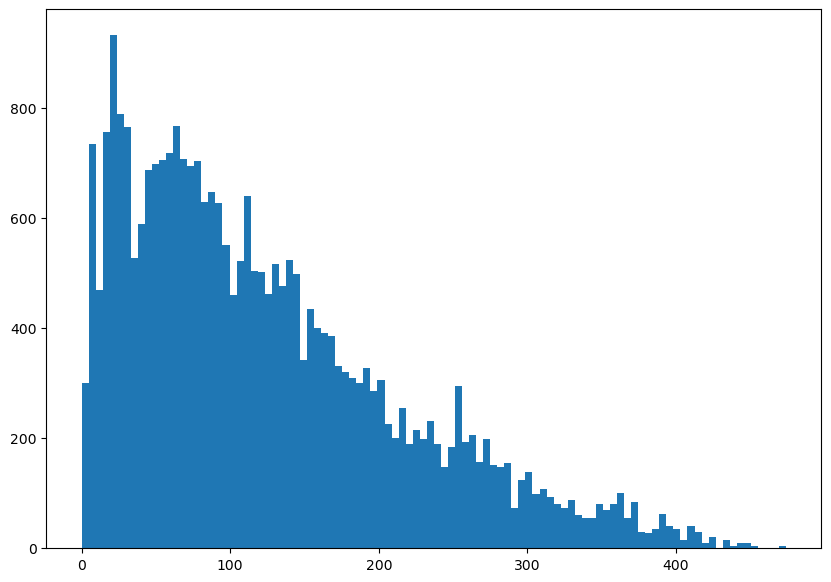

In [101]:
plt.hist(avgs, bins=100)